In [ ]:
# 02 - Dataset Preparation

## Objective

Prepare the DocTamper dataset for deep learning.

This notebook will:
1. Load dataset split information.
2. Connect CSV records to LMDB.
3. Load document images and masks.
4. Inspect image and mask data.
5. Prepare PyTorch tensors.
6. Build Dataset and DataLoader objects.

In [12]:
from pathlib import Path

import lmdb
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from PIL import Image
from io import BytesIO

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "pyproject.toml").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not find project root")
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"

LARGE_LMDB = DATA_DIR / "raw" / "large"
LARGE_SPLIT = DATA_DIR / "splits" / "large_dataset_split.csv"

print("Project:", PROJECT_ROOT)
print("Large dataset:", LARGE_LMDB)
print("Split CSV:", LARGE_SPLIT)
print("PyTorch:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())

Project: /Users/thinyadanaroo/sch_projects/PROM02/PROM02_240291316/doc-forgery-detection
Large dataset: /Users/thinyadanaroo/sch_projects/PROM02/PROM02_240291316/doc-forgery-detection/data/raw/large
Split CSV: /Users/thinyadanaroo/sch_projects/PROM02/PROM02_240291316/doc-forgery-detection/data/splits/large_dataset_split.csv
PyTorch: 2.3.1
MPS available: True


In [13]:
# Load the split Dataset
split_df = pd.read_csv(LARGE_SPLIT)

print("Total samples:", len(split_df))
print("\nSplit distribution:")
print(split_df["split"].value_counts())

split_df.head()

Total samples: 120000

Split distribution:
split
train         96000
validation    12000
test          12000
Name: count, dtype: int64


,sample_id,image_key,label_key,split
0,0,image-000000000,label-000000000,train
1,1,image-000000001,label-000000001,validation
2,2,image-000000002,label-000000002,train
3,3,image-000000003,label-000000003,train
4,4,image-000000004,label-000000004,validation


In [14]:
# Open the LMDB database
env = lmdb.open(
    str(LARGE_LMDB),
    readonly=True,
    lock=False,
    readahead=False,
    max_readers=512,
)

print("LMDB opened successfully")

LMDB opened successfully


In [16]:
# Load one image and its corresponding mask
def load_sample(env, image_key, label_key):
    with env.begin(buffers=False) as txn:
        image_bytes = txn.get(image_key.encode())
        mask_bytes = txn.get(label_key.encode())

    if image_bytes is None:
        raise KeyError(f"Image not found: {image_key}")

    if mask_bytes is None:
        raise KeyError(f"Mask not found: {label_key}")

    image = Image.open(BytesIO(image_bytes)).convert("RGB")
    mask = Image.open(BytesIO(mask_bytes)).convert("L")

    return image, mask

In [17]:
# test the sample
sample = split_df.loc[split_df["split"] == "train"].iloc[1]

image, mask = load_sample(
    env,
    sample["image_key"],
    sample["label_key"],
)

print("Sample ID:", sample["sample_id"])
print("Image size:", image.size)
print("Image mode:", image.mode)
print("Mask size:", mask.size)
print("Mask values:", np.unique(np.array(mask)))

Sample ID: 2
Image size: (512, 512)
Image mode: RGB
Mask size: (512, 512)
Mask values: [  0 255]


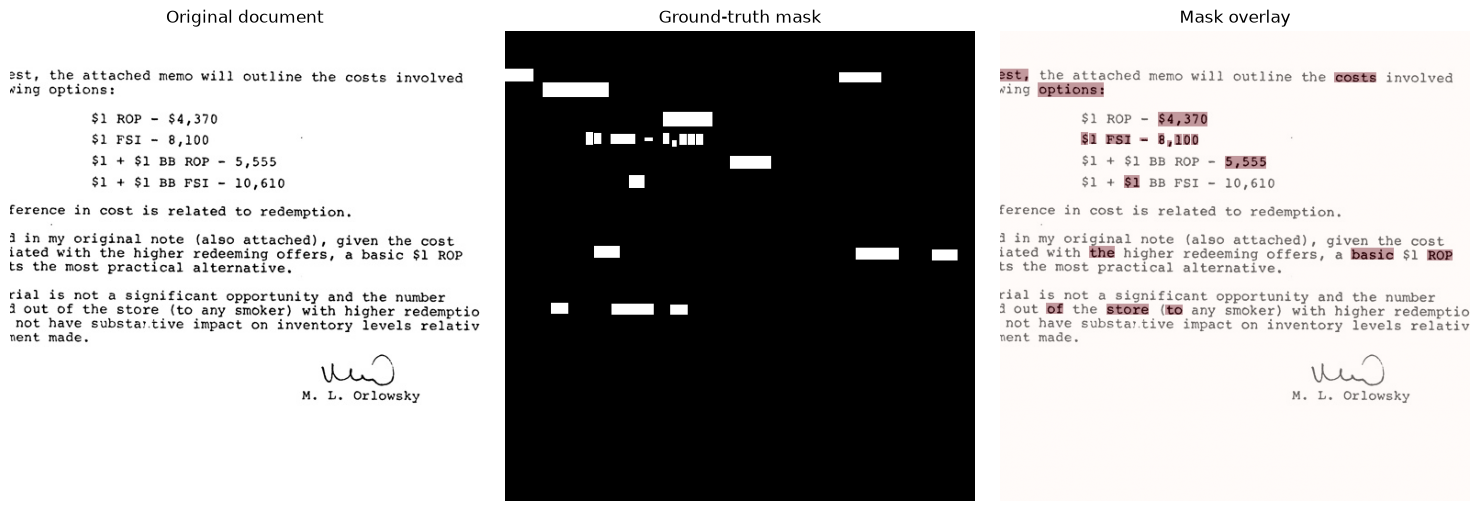

In [18]:
# Visualise the image and mask
image_array = np.array(image)
mask_array = np.array(mask)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_array)
axes[0].set_title("Original document")

axes[1].imshow(mask_array, cmap="gray")
axes[1].set_title("Ground-truth mask")

axes[2].imshow(image_array)
axes[2].imshow(mask_array > 0, cmap="Reds", alpha=0.4)
axes[2].set_title("Mask overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [19]:
# Check the original mask values
# Inspect the original mask values
mask_array = np.array(mask)

unique_values, counts = np.unique(
    mask_array,
    return_counts=True
)

for value, count in zip(unique_values, counts):
    print(f"Pixel value: {value}, Count: {count}")

print("Mask shape:", mask_array.shape)
print("Mask data type:", mask_array.dtype)

Pixel value: 0, Count: 255072
Pixel value: 255, Count: 7072
Mask shape: (512, 512)
Mask data type: uint8


In [20]:
#Convert the image and mask
from torchvision.transforms.functional import to_tensor

# Convert RGB image into a PyTorch tensor
image_tensor = to_tensor(image)

# Convert mask into a binary NumPy array
# Provisional assumption: every non-zero pixel is foreground
binary_mask = (mask_array > 0).astype(np.float32)

# Convert mask into a PyTorch tensor
mask_tensor = torch.from_numpy(binary_mask).unsqueeze(0)

print("Image tensor:")
print("Shape:", image_tensor.shape)
print("Data type:", image_tensor.dtype)
print("Minimum:", image_tensor.min().item())
print("Maximum:", image_tensor.max().item())

print("\nMask tensor:")
print("Shape:", mask_tensor.shape)
print("Data type:", mask_tensor.dtype)
print("Unique values:", torch.unique(mask_tensor))


Image tensor:
Shape: torch.Size([3, 512, 512])
Data type: torch.float32
Minimum: 0.0
Maximum: 1.0

Mask tensor:
Shape: torch.Size([1, 512, 512])
Data type: torch.float32
Unique values: tensor([0., 1.])


In [21]:
# import Dataset
from torch.utils.data import Dataset

In [22]:
import numpy as np
import torch

from PIL import Image
from io import BytesIO
from torchvision.transforms.functional import to_tensor
from torch.utils.data import Dataset


class DocTamperDataset(Dataset):

    def __init__(self, dataframe, env):
        self.samples = dataframe.reset_index(drop=True)
        self.env = env

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        row = self.samples.iloc[index]

        with self.env.begin() as txn:
            image_bytes = txn.get(row["image_key"].encode())
            mask_bytes = txn.get(row["label_key"].encode())

        if image_bytes is None or mask_bytes is None:
            raise KeyError(f"Missing sample: {row['sample_id']}")

        image = Image.open(
            BytesIO(image_bytes)
        ).convert("RGB")

        mask = Image.open(
            BytesIO(mask_bytes)
        ).convert("L")

        image_tensor = to_tensor(image)

        mask_array = np.array(mask)
        binary_mask = (mask_array > 0).astype(np.float32)

        mask_tensor = torch.from_numpy(
            binary_mask
        ).unsqueeze(0)

        return image_tensor, mask_tensor

In [23]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

LARGE_SPLIT = (
    PROJECT_ROOT / "data" / "splits" / "large_dataset_split.csv"
)

split_df = pd.read_csv(LARGE_SPLIT)

print("Total samples:", len(split_df))
print(split_df["split"].value_counts())

Total samples: 120000
split
train         96000
validation    12000
test          12000
Name: count, dtype: int64


In [24]:
print("env:", "env" in globals())
print("DocTamperDataset:", "DocTamperDataset" in globals())
print("split_df:", "split_df" in globals())

env: True
DocTamperDataset: True
split_df: True


In [25]:
# Create a training dataset
train_df = split_df[
    split_df["split"] == "train"
].copy()

train_dataset = DocTamperDataset(
    dataframe=train_df,
    env=env
)

print("Training samples:", len(train_dataset))

Training samples: 96000


In [26]:
# Retrieve one sample 
sample_image, sample_mask = train_dataset[0]

print("Image shape:", sample_image.shape)
print("Mask shape:", sample_mask.shape)

print("Image dtype:", sample_image.dtype)
print("Mask dtype:", sample_mask.dtype)

print("Mask values:", torch.unique(sample_mask))

Image shape: torch.Size([3, 512, 512])
Mask shape: torch.Size([1, 512, 512])
Image dtype: torch.float32
Mask dtype: torch.float32
Mask values: tensor([0., 1.])


In [27]:
from torch.utils.data import DataLoader

In [28]:
BATCH_SIZE = 8

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

print("Number of batches:", len(train_loader))

Number of batches: 12000


In [29]:
# Retrieve the first Batch 

# Get the first batch
images, masks = next(iter(train_loader))

print("Images batch shape:", images.shape)
print("Masks batch shape:", masks.shape)

print("\nImages dtype:", images.dtype)
print("Masks dtype:", masks.dtype)

print("\nImage value range:")
print("Minimum:", images.min().item())
print("Maximum:", images.max().item())

print("\nMask unique values:", torch.unique(masks))

Images batch shape: torch.Size([8, 3, 512, 512])
Masks batch shape: torch.Size([8, 1, 512, 512])

Images dtype: torch.float32
Masks dtype: torch.float32

Image value range:
Minimum: 0.0
Maximum: 1.0

Mask unique values: tensor([0., 1.])


In [ ]:
# Data Validataion before U-net

In [30]:
# Check masks' annotation values 

import numpy as np
from PIL import Image
from io import BytesIO

# Inspect representative samples from each split
for split_name in ["train", "validation", "test"]:

    print(f"\n--- {split_name.upper()} ---")

    samples = split_df[
        split_df["split"] == split_name
    ].head(5)

    for _, row in samples.iterrows():

        with env.begin() as txn:
            mask_bytes = txn.get(
                row["label_key"].encode()
            )

        mask = np.array(
            Image.open(BytesIO(mask_bytes)).convert("L")
        )

        values, counts = np.unique(
            mask,
            return_counts=True
        )

        print(
            f"Sample {row['sample_id']}:",
            dict(zip(values.tolist(), counts.tolist()))
        )



--- TRAIN ---
Sample 0: {0: 257334, 1: 4810}
Sample 2: {0: 255072, 255: 7072}
Sample 3: {0: 261385, 255: 759}
Sample 5: {0: 241683, 255: 20461}
Sample 6: {0: 254966, 255: 7178}

--- VALIDATION ---
Sample 1: {0: 236972, 255: 25172}
Sample 4: {0: 260894, 255: 1250}
Sample 11: {0: 260992, 255: 1152}
Sample 27: {0: 259569, 255: 2575}
Sample 32: {0: 259315, 255: 2829}

--- TEST ---
Sample 12: {0: 260230, 255: 1914}
Sample 22: {0: 260024, 255: 2120}
Sample 24: {0: 261058, 255: 1086}
Sample 25: {0: 253300, 255: 8844}
Sample 37: {0: 260085, 255: 2059}


In [31]:
# Check Data split integrity 

# Check duplicate image and mask keys
print("Duplicate image keys:",
      split_df["image_key"].duplicated().sum())

print("Duplicate label keys:",
      split_df["label_key"].duplicated().sum())

# Check whether image keys are shared across splits
image_split_counts = (
    split_df.groupby("image_key")["split"].nunique()
)

print(
    "Images appearing in multiple splits:",
    (image_split_counts > 1).sum()
)

# Check split distribution
print("\nSplit distribution:")
print(split_df["split"].value_counts())


Duplicate image keys: 0
Duplicate label keys: 0
Images appearing in multiple splits: 0

Split distribution:
split
train         96000
validation    12000
test          12000
Name: count, dtype: int64


In [32]:
import torch
import torch.nn as nn

from docforge.models.unet import DoubleConv

block = DoubleConv(3, 64)

dummy_input = torch.randn(1, 3, 512, 512)

output = block(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([1, 3, 512, 512])
Output shape: torch.Size([1, 64, 512, 512])


In [33]:
from docforge.models.unet import Encoder

encoder = Encoder(in_channels=3)

dummy_input = torch.randn(1, 3, 512, 512)

features = encoder(dummy_input)

for i, feature in enumerate(features, start=1):
    print(f"Encoder {i} output:", feature.shape)


Encoder 1 output: torch.Size([1, 64, 512, 512])
Encoder 2 output: torch.Size([1, 128, 256, 256])
Encoder 3 output: torch.Size([1, 256, 128, 128])
Encoder 4 output: torch.Size([1, 512, 64, 64])


In [34]:
from docforge.models.unet import Bottleneck

bottleneck = Bottleneck()

encoder = Encoder(in_channels=3)

dummy_input = torch.randn(1, 3, 512, 512)

features = encoder(dummy_input)

x4 = features[-1]

bottleneck_output = bottleneck(x4)

print("Encoder output:", x4.shape)
print("Bottleneck output:", bottleneck_output.shape)


Encoder output: torch.Size([1, 512, 64, 64])
Bottleneck output: torch.Size([1, 1024, 32, 32])


In [35]:
import importlib
import docforge.models.unet as unet

importlib.reload(unet)

print("DoubleConv:", hasattr(unet, "DoubleConv"))
print("Encoder:", hasattr(unet, "Encoder"))
print("Bottlenect:", hasattr(unet, "Bottleneck"))

DoubleConv: True
Encoder: True
Bottlenect: True


In [36]:
importlib.reload(unet)

<module 'docforge.models.unet' from '/Users/thinyadanaroo/sch_projects/PROM02/PROM02_240291316/doc-forgery-detection/src/docforge/models/unet.py'>

In [37]:
# Update Bottleneck Test

import importlib
import docforge.models.unet as unet

importlib.reload(unet)

encoder = unet.Encoder(in_channels=3)
bottleneck = unet.Bottleneck()

dummy_input = torch.randn(1, 3, 512, 512)

features = encoder(dummy_input)
x4 = features[-1]

bottleneck_output = bottleneck(x4)

print("Encoder output:", x4.shape)
print("Bottleneck output:", bottleneck_output.shape)


Encoder output: torch.Size([1, 512, 64, 64])
Bottleneck output: torch.Size([1, 1024, 32, 32])


In [38]:
from docforge.models.unet import DecoderBlock

decoder1 = DecoderBlock(
    in_channels=1024,
    skip_channels=512,
    out_channels=512
)

bottleneck_output = torch.randn(1, 1024, 32, 32)
skip_connection = torch.randn(1, 512, 64, 64)

decoder_output = decoder1(bottleneck_output, skip_connection)

print("Decoder output:", decoder_output.shape)

Decoder output: torch.Size([1, 512, 64, 64])


In [39]:
from docforge.models.unet import Decoder

decoder = Decoder()

# Simulate encoder outputs
x1 = torch.randn(1, 64, 512, 512)
x2 = torch.randn(1, 128, 256, 256)
x3 = torch.randn(1, 256, 128, 128)
x4 = torch.randn(1, 512, 64, 64)

# Simulate bottleneck output
bottleneck_output = torch.randn(1, 1024, 32, 32)

decoder_output = decoder(
    bottleneck_output, x1, x2, x3, x4
)

print("Final decoder output:", decoder_output.shape)

Final decoder output: torch.Size([1, 64, 512, 512])


In [40]:
import importlib
import docforge.models.unet as unet

importlib.reload(unet)

model = unet.UNet()

test_input = torch.randn(1, 3, 512, 512)

with torch.no_grad():
    output = model(test_input)

print("Input shape:", test_input.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([1, 3, 512, 512])
Output shape: torch.Size([1, 1, 512, 512])


In [41]:
# TESTING loss function
import torch.nn as nn

# Create a model and sample input
model = unet.UNet()

input_image = torch.randn(1, 3, 512, 512)
target_mask = torch.randint(
    0, 2, (1, 1, 512, 512)
).float()

# Forward pass
prediction = model(input_image)

# Calculate loss
criterion = nn.BCEWithLogitsLoss()
loss = criterion(prediction, target_mask)

print("Prediction shape:", prediction.shape)
print("Target shape:", target_mask.shape)
print("Loss:", loss.item())

Prediction shape: torch.Size([1, 1, 512, 512])
Target shape: torch.Size([1, 1, 512, 512])
Loss: 0.7311974763870239


In [42]:
for split_name in ["train", "validation", "test"]:
    subset = split_df[split_df["split"] == split_name]

    print(f"\n--- {split_name.upper()} ---")

    for index in [0, 1, 2, 3, 4]:
        row = subset.iloc[index]

        _, mask = load_sample(
            env,
            row["image_key"],
            row["label_key"]
        )

        mask_array = np.array(mask)

        print(
            f"Sample {row['sample_id']}:",
            "unique values =", np.unique(mask_array),
            "nonzero pixels =", np.count_nonzero(mask_array)
        )


--- TRAIN ---
Sample 0: unique values = [0 1] nonzero pixels = 4810
Sample 2: unique values = [  0 255] nonzero pixels = 7072
Sample 3: unique values = [  0 255] nonzero pixels = 759
Sample 5: unique values = [  0 255] nonzero pixels = 20461
Sample 6: unique values = [  0 255] nonzero pixels = 7178

--- VALIDATION ---
Sample 1: unique values = [  0 255] nonzero pixels = 25172
Sample 4: unique values = [  0 255] nonzero pixels = 1250
Sample 11: unique values = [  0 255] nonzero pixels = 1152
Sample 27: unique values = [  0 255] nonzero pixels = 2575
Sample 32: unique values = [  0 255] nonzero pixels = 2829

--- TEST ---
Sample 12: unique values = [  0 255] nonzero pixels = 1914
Sample 22: unique values = [  0 255] nonzero pixels = 2120
Sample 24: unique values = [  0 255] nonzero pixels = 1086
Sample 25: unique values = [  0 255] nonzero pixels = 8844
Sample 37: unique values = [  0 255] nonzero pixels = 2059


In [43]:
# Verify the real DATASET Mask
binary_mask = (mask_array > 0).astype(np.float32)

In [44]:
import lmdb

datasets = {
    "LARGE": PROJECT_ROOT / "data/raw/large",
    "SMALL": PROJECT_ROOT / "data/raw/small",
}

for name, path in datasets.items():
    print(f"\n===== {name} DATASET =====")

    database = lmdb.open(
        str(path),
        readonly=True,
        lock=False,
        readahead=False
    )

    with database.begin() as txn:
        print("Metadata:")

        for key, value in txn.cursor():
            if not key.startswith((b"image-", b"label-")):
                print(key, value[:200])

        print("Image 0 exists:", txn.get(b"image-000000000") is not None)
        print("Label 0 exists:", txn.get(b"label-000000000") is not None)

    database.close()


===== LARGE DATASET =====
Metadata:
b'num-samples' b'120000'
Image 0 exists: True
Label 0 exists: True

===== SMALL DATASET =====
Metadata:
b'num-samples' b'2000'
Image 0 exists: True
Label 0 exists: True


In [45]:
from pathlib import Path
import pandas as pd

from docforge.training.dataset import DocTamperDataset

# Load the existing split CSV
split_path = PROJECT_ROOT / "data/splits/large_dataset_split.csv"
split_df = pd.read_csv(split_path)

# Select a small number of training samples
train_df = split_df[split_df["split"] == "train"].head(5)

# Create dataset
dataset = DocTamperDataset(
    dataframe=train_df,
    lmdb_path=PROJECT_ROOT / "data/raw/large"
)

# Load first sample
image, mask = dataset[0]

print("Dataset length:", len(dataset))
print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Image dtype:", image.dtype)
print("Mask dtype:", mask.dtype)
print("Mask values:", torch.unique(mask))

Dataset length: 5
Image shape: torch.Size([3, 512, 512])
Mask shape: torch.Size([1, 512, 512])
Image dtype: torch.float32
Mask dtype: torch.float32
Mask values: tensor([0., 1.])


In [46]:
from torch.utils.data import DataLoader
from docforge.training.dataset import DocTamperDataset

# Create full training dataset
train_df = split_df[split_df["split"] == "train"].copy()

train_dataset = DocTamperDataset(
    dataframe=train_df,
    lmdb_path=PROJECT_ROOT / "data/raw/large"
)

# Create DataLoader
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0
)

print("Training samples:", len(train_dataset))
print("Number of batches:", len(train_loader))

Training samples: 96000
Number of batches: 24000


In [47]:
images, masks = next(iter(train_loader))

print("Images shape:", images.shape)
print("Masks shape:", masks.shape)
print("Image range:", images.min().item(), images.max().item())
print("Mask values:", torch.unique(masks))

Images shape: torch.Size([4, 3, 512, 512])
Masks shape: torch.Size([4, 1, 512, 512])
Image range: 0.0 0.8901960849761963
Mask values: tensor([0., 1.])


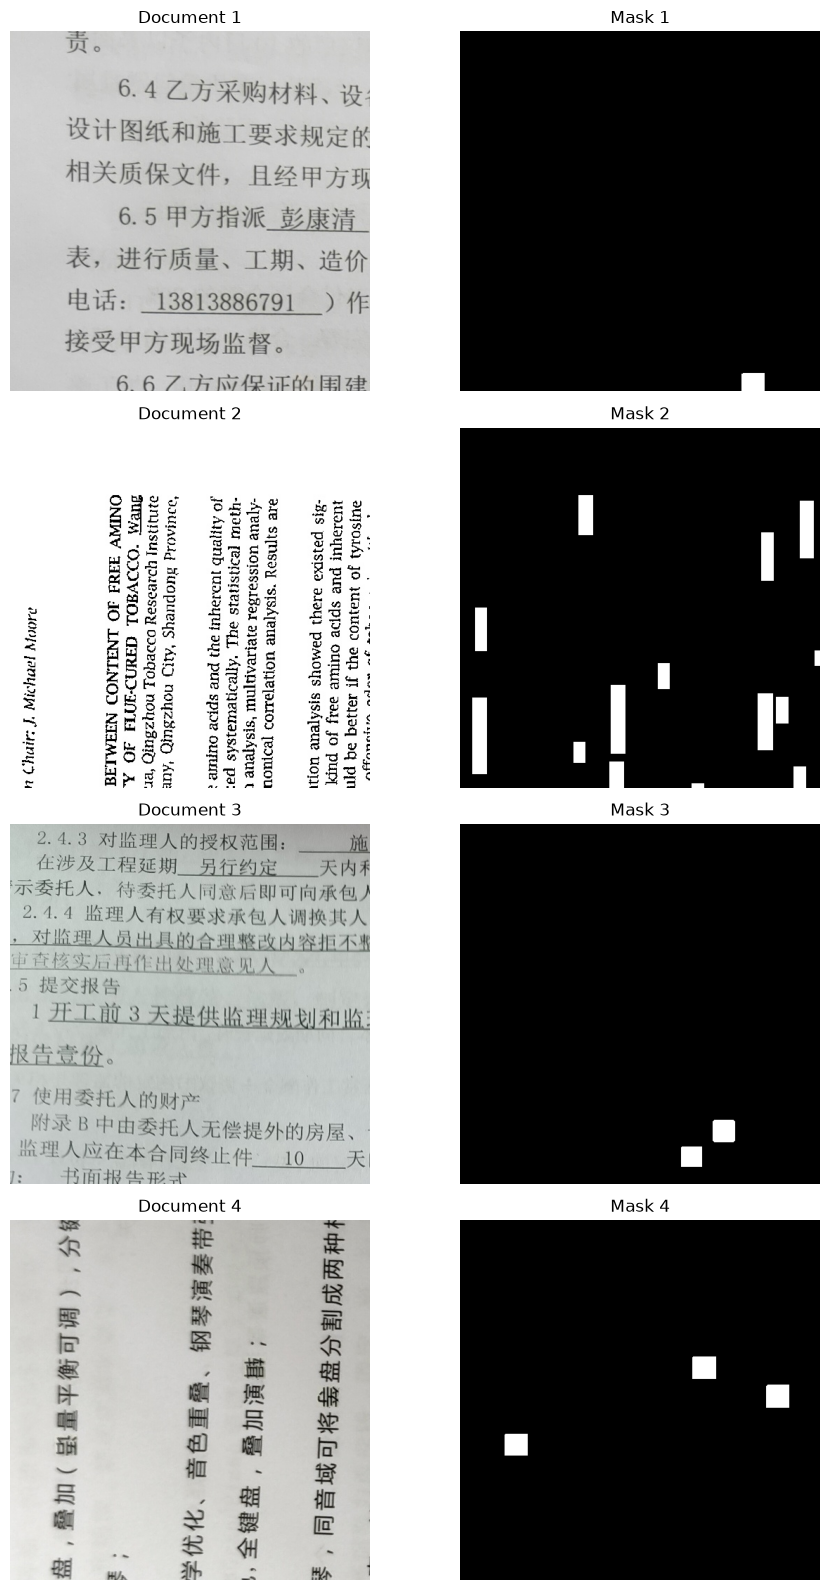

In [48]:
import matplotlib.pyplot as plt

images, masks = next(iter(train_loader))

fig, axes = plt.subplots(4, 2, figsize=(10, 16))

for i in range(4):
    image = images[i].permute(1, 2, 0).numpy()
    mask = masks[i].squeeze(0).numpy()

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"Document {i + 1}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title(f"Mask {i + 1}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()